<a href="https://colab.research.google.com/github/Luis1941905/ISSD_PH/blob/main/Gonzalez_Luis_TP2_PH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

"""
TRABAJO PRÁCTICO: EXTRACCIÓN Y ANÁLISIS DE INFORMACIÓN DE UN PDF

Introducción

En este trabajo se analiza un documento público en formato PDF obtenido desde Internet.
El objetivo es aplicar técnicas de adquisición de datos, extracción de texto,
análisis estructural, recuperación de datos tabulares y procesamiento básico de
lenguaje natural (NLP).

Para ello se utilizarán bibliotecas especializadas de Python que permiten acceder
a los metadatos del documento, recuperar su contenido textual, convertir tablas
a DataFrames y realizar análisis léxico mediante tokenización y cálculo de
frecuencias de palabras.
"""

"""
OBJETIVOS

1. Automatizar la descarga de un archivo PDF desde una fuente pública.
2. Inspeccionar los metadatos del documento.
3. Analizar la estructura del texto extraído.
4. Recuperar información tabular contenida en el PDF.
5. Aplicar técnicas básicas de Procesamiento de Lenguaje Natural.
6. Visualizar las palabras más frecuentes del documento.
"""

In [ ]:
#Instalacion de bibliotecas#
!pip install pymupdf pdfplumber nltk pandas matplotlib requests -q

In [ ]:
#Importamos librerias#
import requests
import fitz
import pdfplumber
import pandas as pd
import nltk
import string
import matplotlib.pyplot as plt

from collections import Counter
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:

#Vamos a trabajar sobre un PDF Informe Panorama del Empleo Asalariado Formal
# y de las Remuneraciones, elaborado por el Área de Empleo,
 #Distribución e Instituciones Laborales (EDIL) del Instituto Interdisciplinario
  #de Economía Política (IIEP), dependiente de la UBA.#

url = "https://economicas.uba.ar/iiep/wp-content/uploads/2025/08/Informe-EDIL.pdf"

response = requests.get(url)

with open("empleo_argentina.pdf", "wb") as archivo:
    archivo.write(response.content)

print("PDF descargado correctamente")

PDF descargado correctamente


In [ ]:
#Abrimos el documento#

pdf = fitz.open("empleo_argentina.pdf")

print("Cantidad de páginas:", pdf.page_count)

Cantidad de páginas: 14


In [ ]:
#Imprimimos los Metadatos#

print("="*50)
print("METADATOS")
print("="*50)

metadata = pdf.metadata

for clave, valor in metadata.items():
    print(f"{clave}: {valor}")

METADATOS
format: PDF 1.7
title: 
author: Anahí Di Lalla
subject: 
keywords: 
creator: Microsoft® Word 2016
producer: Microsoft® Word 2016
creationDate: D:20250818100805-03'00'
modDate: D:20250818102347-03'00'
trapped: 
encryption: None


Se inspeccionaron los metadatos del documento utilizando la biblioteca PyMuPDF.
Entre los datos recuperados se encuentran el título, autor, fecha de creación,
software utilizado y cantidad total de páginas del documento.

In [ ]:
#Extraemos el texto completo#

texto_completo = ""

for pagina in pdf:
    texto_completo += pagina.get_text()

print("Cantidad total de caracteres:", len(texto_completo))

print("\nPrimeros 3000 caracteres:\n")
print(texto_completo[:3000])


Cantidad total de caracteres: 29012

Primeros 3000 caracteres:

INFORME
PANORAMA DEL EMPLEO 
ASALARIADO FORMAL 
Y DE LAS REMUNERACIONES 
AGOSTO 2025
edil-iiep@fce.uba.ar
@edil_iiep
iiep.economicas.uba.ar
iiep.economicas.uba.ar    
 
Sobre EDIL 
El Área de Empleo, Distribución e Instituciones Laborales (EDIL) reúne investigadores del Instituto Interdisciplinario de 
Economía Política (IIEP) que estudian la interrelación entre la dinámica del mercado de trabajo, las instituciones 
laborales, las políticas de empleo y de protección social, y la distribución del ingreso en Argentina y en América Latina.  
Los temas de investigación incluyen, entre otros, la movilidad ocupacional e inestabilidad de ingresos, informalidad 
laboral, nuevas formas de empleo y el futuro del trabajo, cambio tecnológico y empleo, rol e impactos de las 
instituciones laborales, desigualdad y pobreza, políticas activas del mercado de trabajo y shocks macroeconómicos, 
ciclos y dinámica de los salarios y el empleo. 

In [ ]:
#Hacemos un analisis estructural Se analiza cómo se encuentra organizado el texto y qué caracteres actúan como separadores de párrafos o secciones.#

print("Cantidad de \\n:", texto_completo.count("\n"))
print("Cantidad de \\r:", texto_completo.count("\r"))
print("Cantidad de \\t:", texto_completo.count("\t"))

Cantidad de \n: 1505
Cantidad de \r: 0
Cantidad de \t: 0


Al analizar el texto extraído se observa que los párrafos y secciones se
encuentran separados principalmente mediante saltos de línea (\n). La presencia
de tabulaciones y retornos de carro es mínima, indicando que la organización
del documento depende mayormente de la estructura visual del PDF.


In [ ]:
#Extraemos la tabla de pagina3#

tabla = None
pagina_tabla = None

with pdfplumber.open("empleo_argentina.pdf") as documento:

    for numero_pagina, pagina in enumerate(documento.pages):

        tablas = pagina.extract_tables()

        if tablas:
            tabla = tablas[0]
            pagina_tabla = numero_pagina + 1
            break

print("Tabla encontrada en página:", pagina_tabla)

Tabla encontrada en página: 3


In [ ]:
#La convertimos a un dataframe de Pandas#

df = pd.DataFrame(tabla)

df.head()

,0,1,2
0,Empleo (mayo). En miles,None,None
1,,Privado,"+6,0"
2,,Público,"-4,8"
3,,Casas particulares,"-1,0"
4,,Total,"+0,2"


In [ ]:
df.columns = df.iloc[0]

df = df[1:]

df = df.dropna(how="all")

print("Dimensiones:", df.shape)

df.head()

Dimensiones: (11, 3)


,Empleo (mayo). En miles,None,None
1,,Privado,"+6,0"
2,,Público,"-4,8"
3,,Casas particulares,"-1,0"
4,,Total,"+0,2"
5,,None,None


In [ ]:
#Seleccion de texto para NLP#

texto_nlp = pdf[2].get_text()

print(texto_nlp[:2000])

 
 
 
iiep.economicas.uba.ar         
 
 
 
| 3 
 
En síntesis: 
 
 Mantenimiento de los puestos de trabajo en el 
empleo asalariado formal total en mayo. 
 Aumento de 6,0 mil puestos de trabajo en el 
empleo asalariado formal del sector privado. 
 Caída de 4,8 mil puestos de trabajo en el empleo 
asalariado formal del sector público. 
 Caída de mil puestos de trabajo en el empleo 
asalariado formal de casas particulares.  
 Leve caída del salario mínimo real en el mes de 
julio. 
 Mantenimiento del salario promedio real de los 
asalariados formales del sector privado en junio. 
 Leve caída del salario promedio real de los 
asalariados formales del sector público en junio.  
 
 
Variación mensual de los indicadores principales 
Empleo (mayo). En miles 
Privado 
+6,0 
Público 
-4,8 
Casas particulares 
-1,0 
Total 
+0,2 
 
 
Salario mínimo (julio) 
-0,5% 
 
 
Índice de salarios promedio.  Variación mensual. 
INDEC (junio) 
Sector privado 
+0,1% 
Sector público 
-0,3% 
Empleo asal

In [ ]:
#Convertimos a minusculas#

texto_nlp = texto_nlp.lower()

In [ ]:
#Tokenizacion#

tokens = word_tokenize(texto_nlp)

print("Cantidad de tokens:", len(tokens))
print(tokens[:50])

Cantidad de tokens: 467
['iiep.economicas.uba.ar', '|', '3', 'en', 'síntesis', ':', '\uf0b7', 'mantenimiento', 'de', 'los', 'puestos', 'de', 'trabajo', 'en', 'el', 'empleo', 'asalariado', 'formal', 'total', 'en', 'mayo', '.', '\uf0b7', 'aumento', 'de', '6,0', 'mil', 'puestos', 'de', 'trabajo', 'en', 'el', 'empleo', 'asalariado', 'formal', 'del', 'sector', 'privado', '.', '\uf0b7', 'caída', 'de', '4,8', 'mil', 'puestos', 'de', 'trabajo', 'en', 'el', 'empleo']


In [ ]:
#Eliminacion de stop words#

stop_words = set(stopwords.words("spanish"))

tokens_limpios = []

for palabra in tokens:

    if palabra not in stop_words:

        if palabra not in string.punctuation:

            if palabra.isalpha():

                tokens_limpios.append(palabra)

print("Tokens limpios:", len(tokens_limpios))

Tokens limpios: 213


In [ ]:
#Calculo de frecuencias#

frecuencias = Counter(tokens_limpios)

top15 = frecuencias.most_common(15)

for palabra, frecuencia in top15:
    print(f"{palabra} --> {frecuencia}")

empleo --> 11
mayo --> 10
trabajo --> 8
asalariado --> 8
sector --> 8
formal --> 7
mil --> 7
asalariados --> 7
puestos --> 6
total --> 6
privado --> 5
público --> 5
caída --> 4
salario --> 4
mes --> 4


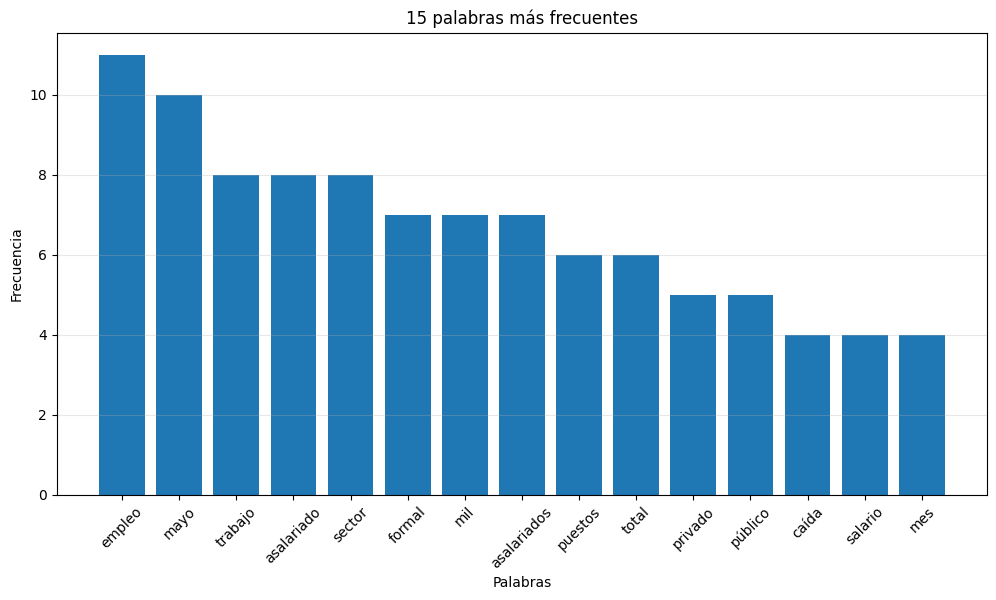

In [ ]:
palabras = [x[0] for x in top15]
cantidades = [x[1] for x in top15]

plt.figure(figsize=(12,6))

plt.bar(palabras, cantidades)

plt.title("15 palabras más frecuentes")
plt.xlabel("Palabras")
plt.ylabel("Frecuencia")

plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.3)

plt.show()